In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [110]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [111]:
df.isnull().sum() * 100/ len(df)

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64

In [112]:
df.drop(columns='deck', inplace=True)

In [113]:
df['age'] = df.age.fillna(value=df['age'].mean())
df['embarked'] = df.embarked.fillna(value=df['embarked'].mode()[0])
df['embark_town'] = df.embark_town.fillna(value=df['embark_town'].mode()[0])

In [114]:
df.isnull().sum() * 100/ len(df)

survived       0.0
pclass         0.0
sex            0.0
age            0.0
sibsp          0.0
parch          0.0
fare           0.0
embarked       0.0
class          0.0
who            0.0
adult_male     0.0
embark_town    0.0
alive          0.0
alone          0.0
dtype: float64

# Outliers removal

<Axes: xlabel='sex', ylabel='age'>

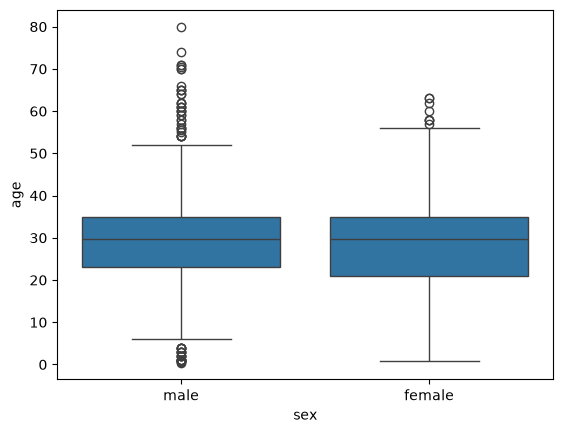

In [115]:
# 1 visualization
sns.boxplot(data=df, y="age", x="sex" )

In [116]:
# IQR method (inter quartile range method)
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1
IQR

np.float64(13.0)

In [117]:
# outliers ko nikalna
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q1 + 1.5 * IQR

df = df[(df['age']> lower_bound) & (df['age']< upper_bound)]

In [118]:
df.shape

(725, 14)

In [119]:
# #Zscore mrthod...upr waly enough h lkn isko smjhna h 
# from scipy as stats

# zscore = np.abs(zscore.stats(df['age']))

# finding and dropping dulicates


In [120]:
# finding dulicates
df.duplicated().sum()

np.int64(107)

# transforming tha data .. isk liye data ko "data normalizaion" krna kahty h 
pip install scikit-learn
ye ML ki main laibrary h normalize krny k liye
to bring data at one scale

In [121]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

In [122]:
#data
df
#normalize columns
col_to_normalize = ['age', 'fare']
# craete the scaler function/tool
scaler = MinMaxScaler()
#fit and transform the data at scaler or vice verca
df[col_to_normalize]=scaler.fit_transform(df[col_to_normalize])
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,0.500000,1,0,0.014151,S,Third,man,True,Southampton,no,False
1,1,1,female,0.921053,1,0,0.139136,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,0.605263,0,0,0.015469,S,Third,woman,False,Southampton,yes,True
3,1,1,female,0.842105,1,0,0.103644,S,First,woman,False,Southampton,yes,False
4,0,3,male,0.842105,0,0,0.015713,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,0.631579,0,0,0.025374,S,Second,man,True,Southampton,no,True
887,1,1,female,0.421053,0,0,0.058556,S,First,woman,False,Southampton,yes,True
888,0,3,female,0.702608,1,2,0.045771,S,Third,woman,False,Southampton,no,False
889,1,1,male,0.605263,0,0,0.058556,C,First,man,True,Cherbourg,yes,True


# log transformation

In [103]:

import seaborn as sns
import numpy as np
import pandas as pd

# 1. Dataset ko dobara load karein taake original data wapis aa jaye
kashti = sns.load_dataset('titanic')

# (Agar aapne CSV se load kiya tha toh yeh use karein: kashti = pd.read_csv('titanic.csv'))

# 2. Ab missing values fill karein
kashti['age'] = kashti['age'].fillna(kashti['age'].median())
kashti['fare'] = kashti['fare'].fillna(kashti['fare'].median())

# 3. Ab Log transformation karein (brackets ka khayal rakhein)
kashti['age'] = np.log1p(kashti['age'])
kashti['fare'] = np.log1p(kashti['fare'])

# 4. Check karein ke ab numbers aa rahe hain
print(kashti['age'].head())

0    3.135494
1    3.663562
2    3.295837
3    3.583519
4    3.583519
Name: age, dtype: float64


<Axes: xlabel='sex', ylabel='fare'>

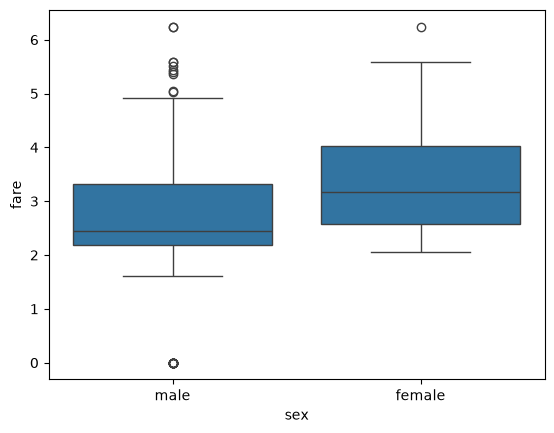

In [104]:
sns.boxplot(data=kashti, x="sex", y="fare")

# organizing the data
ye isk liye krty h ?... apny smj k liye ya logo ko dikhany k liye

In [123]:
df['family_size']=df['sibsp'] + df['parch']

<Axes: xlabel='family_size', ylabel='Count'>

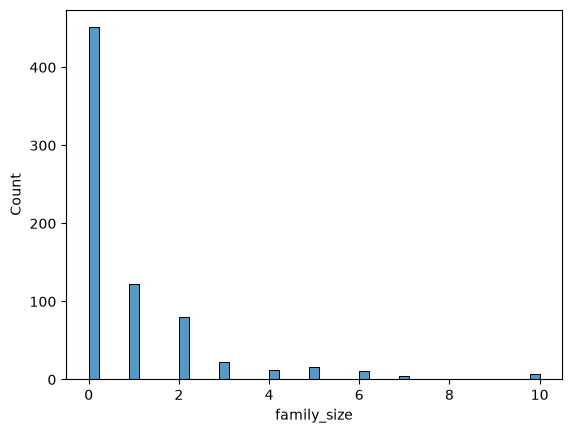

In [106]:
sns.histplot(df['family_size'])

In [107]:
df = df.rename(columns={'survived':'survival'})
df.columns

Index(['survival', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone', 'family_size'],
      dtype='str')

In [108]:
table = pd.pivot_table(df, values='fare', index='pclass',
    columns="survival", aggfunc=np.sum)
table

survival,0,1
pclass,,
1,5.730072,19.264127
2,2.920721,2.879675
3,8.783462,2.922649


In [124]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,family_size
0,0,3,male,0.500000,1,0,0.014151,S,Third,man,True,Southampton,no,False,1
1,1,1,female,0.921053,1,0,0.139136,C,First,woman,False,Cherbourg,yes,False,1
2,1,3,female,0.605263,0,0,0.015469,S,Third,woman,False,Southampton,yes,True,0
3,1,1,female,0.842105,1,0,0.103644,S,First,woman,False,Southampton,yes,False,1
4,0,3,male,0.842105,0,0,0.015713,S,Third,man,True,Southampton,no,True,0


In [125]:
# saving the wrangles the data
df.to_csv('preprocessed_data.csv')